In [3]:
import pandas as pd
data=pd.read_csv("Customer_Purchase_Trend_DirtyData.csv")
data.shape #rows and cols

(5000, 11)

In [5]:
data.isnull().sum() # null values in columns

OrderID          0
CustomerID       0
OrderDate        0
Region          40
Category        40
Product          0
Quantity         0
UnitPrice        0
Revenue         30
PaymentMode     40
CustomerType     0
dtype: int64

In [4]:
data.duplicated().sum() # check duplicate values

np.int64(0)

In [5]:
data[data['Quantity'] < 0] # check invalid quantity

,OrderID,CustomerID,OrderDate,Region,Category,Product,Quantity,UnitPrice,Revenue,PaymentMode,CustomerType
633,50634,1102,2023-03-08,North,Home Decor,Product C,-1,921,1842.0,Cash on Delivery,Repeat
1324,51325,1472,2024-11-06,North,Home Decor,Product B,-1,1542,6168.0,Cash on Delivery,Repeat
1406,51407,1798,2023-09-21,South,Beauty,Product B,-1,1078,3234.0,Net Banking,Repeat
1459,51460,1771,2024-06-11,East,Home Decor,Product A,-1,1792,3584.0,Net Banking,Repeat
1578,51579,1316,2023-04-16,East,Electronics,Product F,-1,1240,1240.0,Net Banking,Repeat
1690,51691,1454,2024-10-11,South,Beauty,Product C,-1,1934,7736.0,Cash on Delivery,Repeat
2360,52361,1187,2024-10-19,South,Home Decor,Product B,-1,1164,5820.0,Card,Repeat
2563,52564,1231,2023-05-30,South,Electronics,Product D,-1,185,740.0,Net Banking,Repeat
2829,52830,1258,2023-09-21,West,Fashion,Product D,-1,1595,4785.0,Net Banking,New
3643,53644,1602,2023-03-29,South,Fashion,Product D,-1,102,102.0,Card,New


In [11]:
data['Region'] = data['Region'].fillna(data['Region'].mode()[0])
data['Category'] = data['Category'].fillna(data['Category'].mode()[0])
data['PaymentMode'] = data['PaymentMode'].fillna(data['PaymentMode'].mode()[0])
data['Revenue'] = data['Revenue'].fillna(data['Revenue'].median())     # handle missing values

In [12]:
data = data[data['Quantity'] > 0] #remove negative quantity rows

In [13]:
data['OrderDate'] = pd.to_datetime(data['OrderDate']) # convert date to datetime

In [14]:
data.isnull().sum() #recheck cleaned data

OrderID         0
CustomerID      0
OrderDate       0
Region          0
Category        0
Product         0
Quantity        0
UnitPrice       0
Revenue         0
PaymentMode     0
CustomerType    0
dtype: int64

In [15]:
data['Revenue'].sum()  # total revenue EDA1

np.float64(15532679.0)

In [26]:
category_sales = data.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
category_sales   # top product categories by revenue EDA2

Category
Groceries      3357615.0
Fashion        3135277.0
Home Decor     3103745.0
Electronics    3045976.0
Beauty         2890066.0
Name: Revenue, dtype: float64

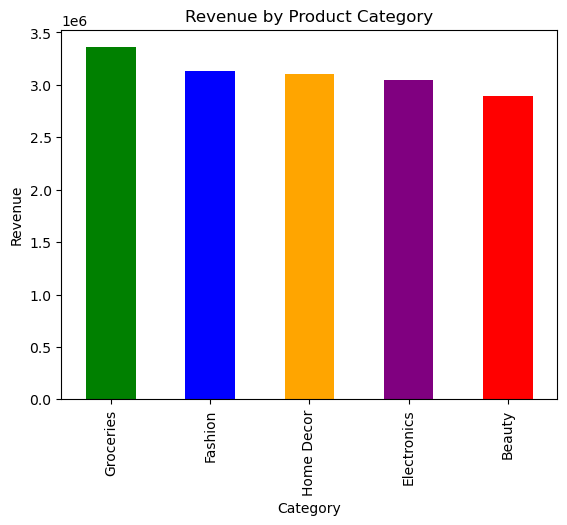

In [37]:
import matplotlib.pyplot as plt
category_sales.plot(kind='bar',color=['green','blue','orange','purple','red'])
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.show()

In [27]:
region_sales = data.groupby('Region')['Revenue'].sum().sort_values(ascending=False)
region_sales   # Region wise revenue EDA3

Region
South    3993926.0
East     3942181.0
West     3913695.0
North    3682877.0
Name: Revenue, dtype: float64

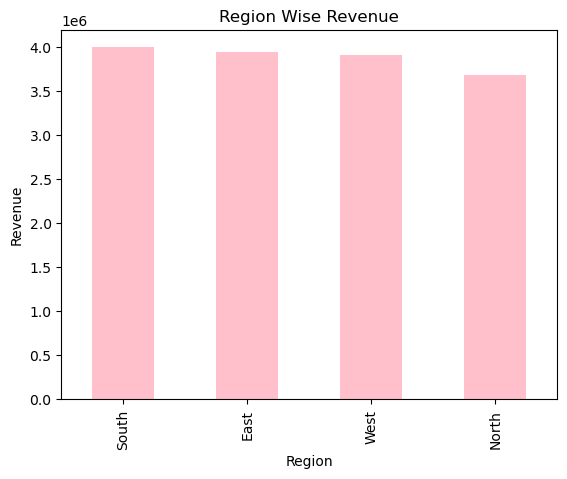

In [38]:
region_sales.plot(kind='bar',color='pink')
plt.title("Region Wise Revenue")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

In [29]:
payment_analysis = data['PaymentMode'].value_counts()
payment_analysis #Payment mode analysis EDA4

PaymentMode
Cash on Delivery    1296
Card                1235
UPI                 1225
Net Banking         1224
Name: count, dtype: int64

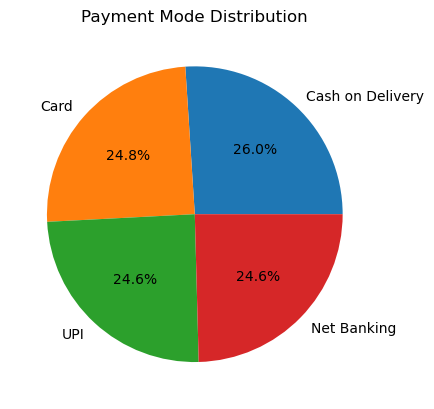

In [30]:
payment_analysis.plot(kind='pie', autopct='%1.1f%%')
plt.title("Payment Mode Distribution")
plt.ylabel("")
plt.show()

In [43]:
data['Month'] = data['OrderDate'].dt.month_name() # extract month
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
monthly_sales = data.groupby('Month')['Revenue'].sum().reindex(month_order) # monthly revenue EDA5
monthly_sales

Month
January      1241584.0
February     1145241.0
March        1351404.0
April        1315744.0
May          1377723.0
June         1299192.0
July         1313611.0
August       1257091.0
September    1224438.0
October      1404209.0
November     1350545.0
December     1251897.0
Name: Revenue, dtype: float64

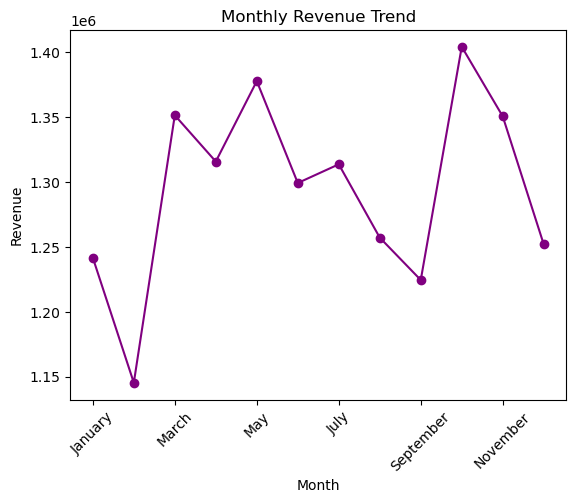

In [44]:
monthly_sales.plot(kind='line', marker='o', color='purple')
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

In [45]:
customer_type = data.groupby('CustomerType')['Revenue'].sum()
customer_type  #EDA6

CustomerType
New        5383325.0
Repeat    10149354.0
Name: Revenue, dtype: float64

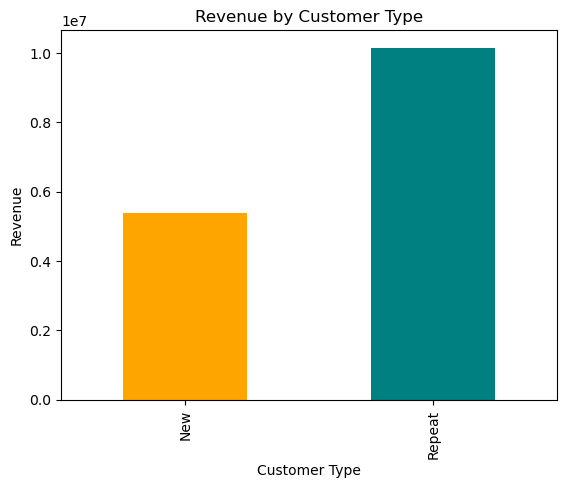

In [46]:
customer_type.plot(kind='bar', color=['orange','teal'])
plt.title("Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Revenue")
plt.show()

In [47]:
top_customers = data.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10)
top_customers # top 10 customers by revenue EDA7

CustomerID
1673    52102.0
1038    51332.0
1754    50087.0
1308    49321.0
1239    46452.0
1368    44901.0
1313    44660.0
1645    44582.0
1059    44422.0
1349    43892.0
Name: Revenue, dtype: float64

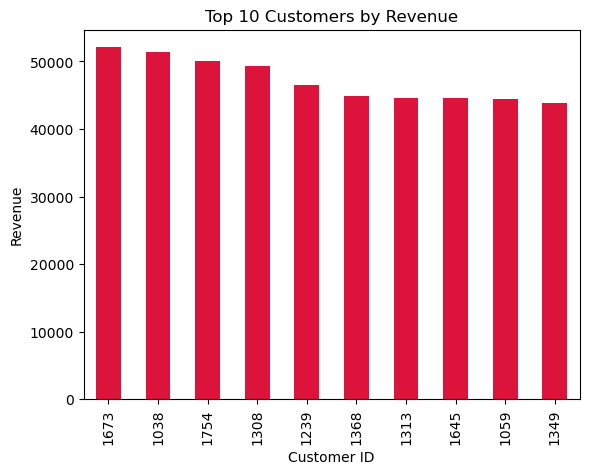

In [48]:
top_customers.plot(kind='bar', color='crimson')
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")
plt.show()

In [49]:
data['Revenue'].mean() #avg order value

np.float64(3119.011847389558)

In [50]:
data.head() # final clean data

,OrderID,CustomerID,OrderDate,Region,Category,Product,Quantity,UnitPrice,Revenue,PaymentMode,CustomerType,Month
0,50001,1704,2023-11-24,West,Electronics,Product E,2,1471,2942.0,Cash on Delivery,Repeat,November
1,50002,1081,2023-06-05,West,Home Decor,Product F,2,566,1132.0,Net Banking,Repeat,June
2,50003,1092,2023-09-09,North,Beauty,Product C,2,121,242.0,UPI,Repeat,September
3,50004,1338,2023-11-05,North,Groceries,Product C,4,1772,7088.0,Net Banking,Repeat,November
4,50005,1270,2024-11-10,West,Groceries,Product C,2,1547,3094.0,Cash on Delivery,New,November
